In [56]:
import pandas as pd
import matplotlib.pyplot as plt

linear_table_walk_files = []
linear_table_walk_ft_measurements = {}

no_collisions_files = []
no_collision_ft_measurements = {}

for i in range(8, 24):
    linear_table_walk_files.append(f"../measurements/hash_table_size/linear_table_walk/{i}b_ft.txt")
    no_collisions_files.append(f"../measurements/hash_table_size/no_collision_handling/{i}b_ft.txt")
for file in linear_table_walk_files:
    with open(file, "r") as f:
        bits = file.split("/")[-1].split("b")[0]
        lines = f.readlines()
        pps_l = []
        cycles_l = []
        for line in lines:
            split_line = line.split(",")

            split_pps = split_line[0].split(":")
            pps = float(split_pps[1].strip())
            
            split_cycles = split_line[1].split(":")
            cycles = float(split_cycles[1].strip())
            pps_l.append(pps)
            cycles_l.append(cycles)
        linear_table_walk_ft_measurements[bits] = {"pps": pd.Series(pps_l).median(), "cycles": pd.Series(cycles_l).median()}
for file in no_collisions_files:
    with open(file, "r") as f:
        bits = file.split("/")[-1].split("b")[0]
        lines = f.readlines()
        pps_l = []
        cycles_l = []
        for line in lines:
            split_line = line.split(",")

            split_pps = split_line[0].split(":")
            pps = float(split_pps[1].strip())
            
            split_cycles = split_line[1].split(":")
            cycles = float(split_cycles[1].strip())
            pps_l.append(pps)
            cycles_l.append(cycles)
        no_collision_ft_measurements[bits] = {"pps": pd.Series(pps_l).median(), "cycles": pd.Series(cycles_l).median()}

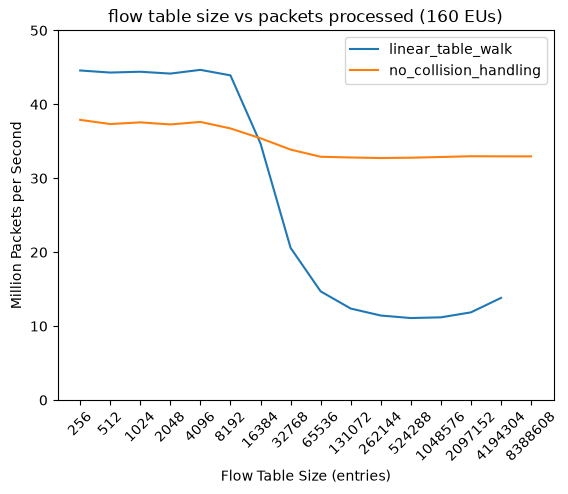

In [57]:
plt.plot([f"{pow(2, int(bits))}" for bits in linear_table_walk_ft_measurements.keys()], [linear_table_walk_ft_measurements[bits]["pps"] for bits in linear_table_walk_ft_measurements.keys()], label="linear_table_walk")
plt.plot([f"{pow(2, int(bits))}" for bits in no_collision_ft_measurements.keys()], [no_collision_ft_measurements[bits]["pps"] for bits in no_collision_ft_measurements.keys()], label="no_collision_handling")
plt.xlabel("Flow Table Size (entries)")
plt.ylabel("Million Packets per Second")
plt.ylim(0, 50)
plt.xticks(rotation=45)
plt.title("flow table size vs packets processed (160 EUs)")
plt.legend()
plt.savefig("flow_table_size_vs_pps.png", bbox_inches="tight")
plt.show()

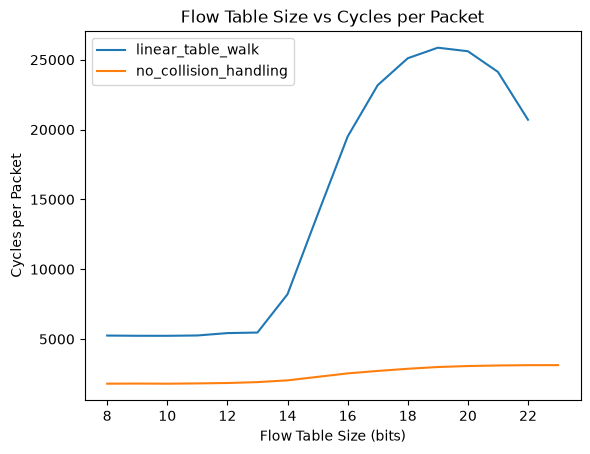

In [58]:
plt.plot([int(bits) for bits in linear_table_walk_ft_measurements.keys()], [linear_table_walk_ft_measurements[bits]["cycles"] for bits in linear_table_walk_ft_measurements.keys()], label="linear_table_walk")
plt.plot([int(bits) for bits in no_collision_ft_measurements.keys()], [no_collision_ft_measurements[bits]["cycles"] for bits in no_collision_ft_measurements.keys()], label="no_collision_handling")
plt.xlabel("Flow Table Size (bits)")
plt.ylabel("Cycles per Packet")
plt.title("Flow Table Size vs Cycles per Packet")
plt.legend()
plt.show()